# Part 3: Classic Machine Learning Projects

Covers Project: Predicting Heart Disease through Project: A Movie Recommender from Ratings. The [README](README.md) has the same content with the full table of contents; datasets and versions are listed in its Setup section.

In [1]:
# Shared setup: imports and paths used throughout. Run this cell first.
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # keep TensorFlow's start-up logs quiet
from pathlib import Path
import logging, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="(Degrees of freedom|divide by zero|invalid value)")  # sparse correlations
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)  # Prophet's backend is chatty
logging.getLogger("tensorflow").setLevel(logging.ERROR)
DATA = Path("data")
IMAGES = Path("images")                                   # animations are written here
MODELS = Path("models")                                   # saved models
IMAGES.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
np.random.seed(42)                                        # for the classic np.random API
rng = np.random.default_rng(42)                           # for new code
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})

print("pandas", pd.__version__, "| NumPy", np.__version__)

pandas 3.0.5 | NumPy 2.5.3


<a id="8-project-predicting-heart-disease"></a>

## 8. Project: Predicting Heart Disease

Time to put the framework and the scikit-learn workflow together on one question: *given a patient's clinical
measurements, can we predict whether they have heart disease?*

<a id="framing-the-problem"></a>

### Framing the Problem

- **Problem:** binary classification, heart disease or not.
- **Data:** the Cleveland heart-disease dataset from the UCI Machine Learning Repository: 303 patients, 13 features and a
  `target` column.
- **Evaluation:** a concrete goal makes the project decidable. Here: *if we can reach 95% accuracy in a proof of concept,
  we'll pursue it.*
- **Features:** understand every column before modelling. Becoming a subject-matter expert on the data is part of the job.

| Column | Meaning |
|---|---|
| `age`, `sex` | age in years; 1 = male, 0 = female |
| `cp` | chest pain type: 0 typical angina, 1 atypical angina, 2 non-anginal pain, 3 asymptomatic |
| `trestbps` | resting blood pressure (mm Hg) |
| `chol` | serum cholesterol (mg/dl) |
| `fbs` | fasting blood sugar > 120 mg/dl (1 = true) |
| `restecg` | resting ECG result (0–2) |
| `thalach` | maximum heart rate achieved |
| `exang` | exercise-induced angina (1 = yes) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | slope of the peak exercise ST segment (0–2) |
| `ca` | number of major vessels coloured by fluoroscopy (0–3) |
| `thal` | thalium stress result (1 normal, 2 fixed defect, 3 reversible defect) |
| `target` | 1 = heart disease, 0 = no heart disease |

<a id="exploratory-data-analysis"></a>

### Exploratory Data Analysis

Exploration answers a few questions before any modelling. What are we predicting? What types of data do we have? What's
missing, and where are the outliers? Could features be added, changed or removed?

The classes here are roughly balanced (54% / 46%) and nothing is missing, which is a good start.

(303, 14)
target
1    0.545
0    0.455
Name: proportion, dtype: float64
Missing values: 0


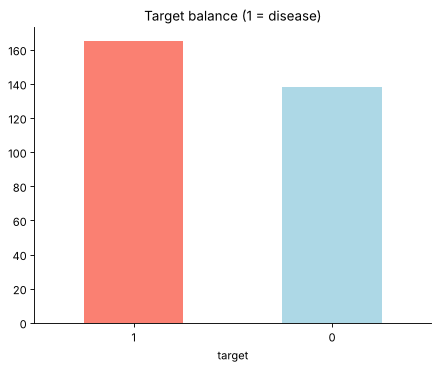

In [2]:
heart_disease = pd.read_csv(DATA / "heart-disease.csv")
print(heart_disease.shape)
print(heart_disease["target"].value_counts(normalize=True).round(3))
print("Missing values:", int(heart_disease.isna().sum().sum()))
heart_disease["target"].value_counts().plot(kind="bar", color=["salmon", "lightblue"], rot=0,
                                            title="Target balance (1 = disease)")
plt.show()

Next, compare the target against features one at a time:

- **Sex:** in this data about 75% of women have heart disease versus about 45% of men. Guessing from sex alone would be right
  roughly 61% of the time, which makes a useful **heuristic baseline** any model must beat.
- **Age vs maximum heart rate:** younger patients reach higher heart rates, and higher heart rates go with disease here.
- **Chest-pain type:** "atypical angina" (`cp = 1`) is surprisingly associated with disease. That's a question to take to
  a domain expert.
- **Correlation matrix:** `exang` correlates negatively with the target, while `cp` and `thalach` correlate positively.

These patterns describe this dataset, and they don't necessarily hold in the wider population.

sex      0    1
target         
0       24  114
1       72   93 



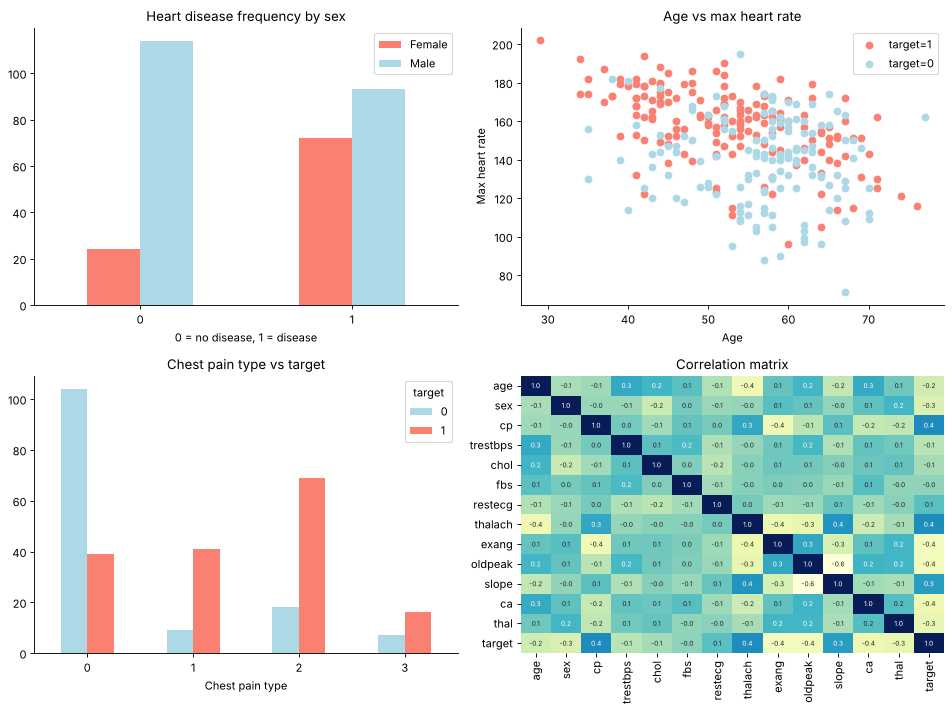

In [3]:
import seaborn as sns

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
print(pd.crosstab(heart_disease["target"], heart_disease["sex"]), "\n")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
pd.crosstab(heart_disease["target"], heart_disease["sex"]).plot(kind="bar", ax=axes[0, 0], rot=0,
                                                                  color=["salmon", "lightblue"])
axes[0, 0].set(title="Heart disease frequency by sex", xlabel="0 = no disease, 1 = disease")
axes[0, 0].legend(["Female", "Male"])

for target, colour in [(1, "salmon"), (0, "lightblue")]:
    subset = heart_disease[heart_disease["target"] == target]
    axes[0, 1].scatter(subset["age"], subset["thalach"], c=colour, label=f"target={target}")
axes[0, 1].set(title="Age vs max heart rate", xlabel="Age", ylabel="Max heart rate"); axes[0, 1].legend()

pd.crosstab(heart_disease["cp"], heart_disease["target"]).plot(kind="bar", ax=axes[1, 0], rot=0,
                                                                 color=["lightblue", "salmon"])
axes[1, 0].set(title="Chest pain type vs target", xlabel="Chest pain type")

sns.heatmap(heart_disease.corr(), annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1, 1], cbar=False,
            annot_kws={"size": 6})
axes[1, 1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

<a id="baseline-models"></a>

### Baseline Models

Split 80/20 with a fixed seed, never let the model see the test set, and try three different kinds of model: **logistic
regression** (a linear classifier, despite the name), **k-nearest neighbours** and a **random forest**. A small
`fit_and_score` helper keeps the comparison fair.

`LogisticRegression(max_iter=1000)` avoids the convergence warning that the default 100 iterations trigger on these unscaled
features. Scaling the features in a pipeline is the cleaner fix (see the exercise in section 7).

{'Logistic Regression': 0.885, 'KNN': 0.689, 'Random Forest': 0.836}


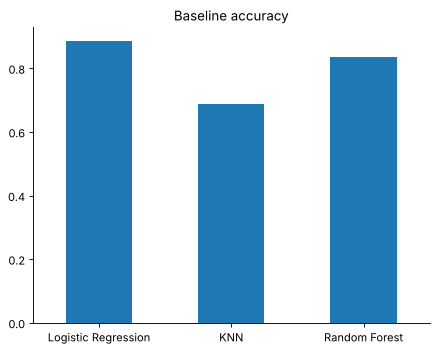

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "KNN": KNeighborsClassifier(),
          "Random Forest": RandomForestClassifier()}

def fit_and_score(models, X_train, X_test, y_train, y_test):
    """Fit each model and return its test accuracy."""
    np.random.seed(42)
    return {name: model.fit(X_train, y_train).score(X_test, y_test) for name, model in models.items()}

model_scores = fit_and_score(models, X_train, X_test, y_train, y_test)
print({k: round(v, 3) for k, v in model_scores.items()})
pd.DataFrame(model_scores, index=["accuracy"]).T.plot.bar(rot=0, legend=False, title="Baseline accuracy")
plt.show()

<a id="tuning-knn-by-hand"></a>

### Tuning KNN by Hand

Manual tuning is just a loop: change one hyperparameter with `set_params()`, refit, and record the training and test
scores. KNN tops out around 75%, well behind the other two, so it's dropped.

Best test accuracy: 75.41% at k=11


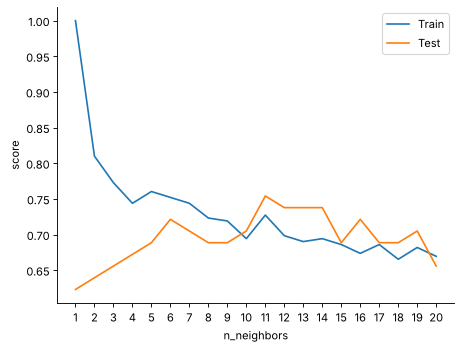

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

knn = KNeighborsClassifier()
neighbors, train_scores, test_scores = range(1, 21), [], []
for k in neighbors:
    knn.set_params(n_neighbors=k).fit(X_train, y_train)
    train_scores.append(knn.score(X_train, y_train)); test_scores.append(knn.score(X_test, y_test))

print(f"Best test accuracy: {max(test_scores) * 100:.2f}% at k={neighbors[int(np.argmax(test_scores))]}")
plt.plot(neighbors, train_scores, label="Train"); plt.plot(neighbors, test_scores, label="Test")
plt.xticks(range(1, 21)); plt.xlabel("n_neighbors"); plt.ylabel("score"); plt.legend(); plt.show()

<a id="tuning-logistic-regression-and-the-random-forest"></a>

### Tuning Logistic Regression and the Random Forest

`RandomizedSearchCV` explores logistic regression (`C` on a log scale) and the random forest (`n_estimators`, `max_depth`,
`min_samples_split`, `min_samples_leaf`). Logistic regression stays on top, so `GridSearchCV` refines its `C` over 30
values. Researching each model's hyperparameters in its documentation is worth the time.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

log_reg_grid = {"C": np.logspace(-4, 4, 20), "solver": ["liblinear"]}
rf_grid = {"n_estimators": np.arange(10, 1000, 50), "max_depth": [None, 3, 5, 10],
           "min_samples_split": np.arange(2, 20, 2), "min_samples_leaf": np.arange(1, 20, 2)}

rs_log_reg = RandomizedSearchCV(LogisticRegression(), log_reg_grid, cv=5, n_iter=20, random_state=42).fit(X_train, y_train)
rs_rf = RandomizedSearchCV(RandomForestClassifier(n_jobs=-1, random_state=42), rf_grid, cv=5, n_iter=20,
                           random_state=42).fit(X_train, y_train)
print("Randomized logistic regression:", round(rs_log_reg.score(X_test, y_test), 3), rs_log_reg.best_params_)
print("Randomized random forest:      ", round(rs_rf.score(X_test, y_test), 3))

gs_log_reg = GridSearchCV(LogisticRegression(), {"C": np.logspace(-4, 4, 30), "solver": ["liblinear"]},
                          cv=5).fit(X_train, y_train)
print("Grid logistic regression:      ", round(gs_log_reg.score(X_test, y_test), 3), gs_log_reg.best_params_)

Randomized logistic regression: 0.885 {'solver': 'liblinear', 'C': np.float64(0.23357214690901212)}
Randomized random forest:       0.869


Grid logistic regression:       0.885 {'C': np.float64(0.20433597178569415), 'solver': 'liblinear'}


<a id="evaluating-beyond-accuracy"></a>

### Evaluating Beyond Accuracy

For a medical model, the costly mistake is a **false negative**: telling a sick patient they're fine. So look at the ROC
curve, the confusion matrix and the classification report, and report **cross-validated** precision, recall and F1
rather than the numbers from one split.

              precision    recall  f1-score   support

           0       0.89      0.86      0.88        29
           1       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61



{'accuracy': np.float64(0.845), 'precision': np.float64(0.821), 'recall': np.float64(0.921), 'f1': np.float64(0.867)}


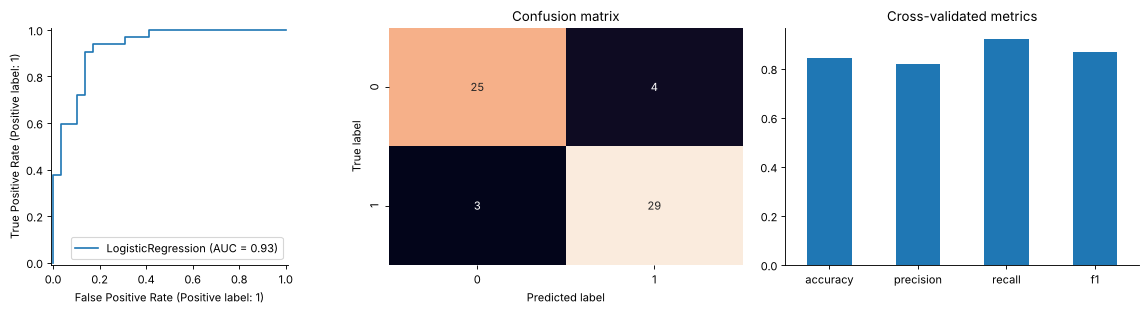

In [7]:
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score, train_test_split

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

best_C = 0.20433597178569418                        # best value found by the grid search above
clf = LogisticRegression(C=best_C, solver="liblinear").fit(X_train, y_train)
y_preds = clf.predict(X_test)
print(classification_report(y_test, y_preds))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=axes[0])
sns.heatmap(confusion_matrix(y_test, y_preds), annot=True, cbar=False, ax=axes[1])
axes[1].set(xlabel="Predicted label", ylabel="True label", title="Confusion matrix")

cv_metrics = {m: cross_val_score(clf, X, y, cv=5, scoring=m).mean() for m in ["accuracy", "precision", "recall", "f1"]}
pd.Series(cv_metrics).plot.bar(ax=axes[2], rot=0, title="Cross-validated metrics")
print({k: round(v, 3) for k, v in cv_metrics.items()})
plt.tight_layout(); plt.show()

<a id="which-features-matter"></a>

### Which Features Matter

For logistic regression, the coefficients in `coef_` act as feature importance. Positive values push the prediction
towards disease, and negative values push it away. They line up with the exploration: `sex` has a strong negative
coefficient (in this data, the disease rate drops as `sex` goes from 0 to 1), and `slope` a positive one.

**Watch out:** coefficients are only comparable when features share a scale. Standardize first, or use model-agnostic
permutation importance, which is covered in the
[Data Preparation reference](https://github.com/rokon-uddin/data-preparation-reference).

sex        -0.914
thal       -0.670
ca         -0.639
exang      -0.562
oldpeak    -0.494
fbs        -0.021
trestbps   -0.015
chol       -0.003
age         0.007
thalach     0.028
restecg     0.322
slope       0.371
cp          0.705
dtype: float64


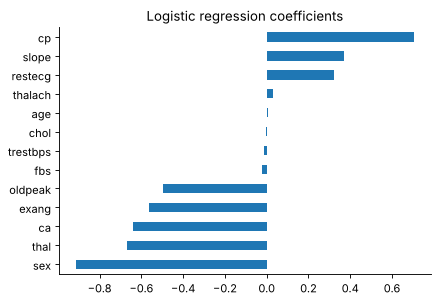

target   0    1
slope          
0       12    9
1       91   49
2       35  107


In [8]:
from sklearn.linear_model import LogisticRegression

heart_disease = pd.read_csv(DATA / "heart-disease.csv")
X, y = heart_disease.drop(columns="target"), heart_disease["target"]
clf = LogisticRegression(C=0.20433597178569418, solver="liblinear").fit(X, y)

feature_importance = pd.Series(clf.coef_[0], index=X.columns).sort_values()
print(feature_importance.round(3))
feature_importance.plot.barh(title="Logistic regression coefficients", figsize=(6, 4)); plt.show()
print(pd.crosstab(heart_disease["slope"], heart_disease["target"]))

<a id="where-this-leaves-us"></a>

### Where This Leaves Us

The tuned model reaches about 88% on the test split, which is short of the 95% goal. The honest options are to collect more
data, try stronger models (gradient boosting such as XGBoost, LightGBM or CatBoost), keep improving the current ones, or
decide the current performance is good enough for its purpose and share it. Missing a target is a normal outcome. It's
the framework that tells you so early.

<a id="cheatsheet-classification-project"></a>

### Cheatsheet: Classification Project

```python
df["target"].value_counts(normalize=True); pd.crosstab(df["target"], df["sex"]); sns.heatmap(df.corr(), annot=True)
models = {"lr": LogisticRegression(max_iter=1000), "knn": KNeighborsClassifier(), "rf": RandomForestClassifier()}
RandomizedSearchCV(LogisticRegression(), {"C": np.logspace(-4, 4, 20), "solver": ["liblinear"]}, cv=5, n_iter=20)
RocCurveDisplay.from_estimator(clf, X_test, y_test); classification_report(y_test, y_preds)
cross_val_score(clf, X, y, cv=5, scoring="recall"); pd.Series(clf.coef_[0], index=X.columns)
```

<a id="9-naive-bayes-and-turning-text-into-numbers"></a>

## 9. Naive Bayes and Turning Text into Numbers

The two text projects use Naive Bayes, a classifier that's over 60 years old and still a strong first choice for text:
it trains in a fraction of a second, needs little data, and is easy to interpret. First the probability behind it, then
how to make text something a model can read.

<a id="bayes-theorem-with-a-picture"></a>

### Bayes' Theorem with a Picture

Imagine a bank classifying customers as ready to retire or not from two features, age and savings. We have 60 past
customers: 40 who retired (blue) and 20 who didn't (red). A new customer arrives, `X`. Which class is more likely?

Bayes' theorem combines three ingredients into the **posterior** probability of each class given the data:

$$P(\text{class} \mid X) = \frac{P(X \mid \text{class}) \cdot P(\text{class})}{P(X)}$$

- **Prior** $P(\text{class})$: before looking at `X`, how common is each class? 40/60 blue, 20/60 red.
- **Likelihood** $P(X \mid \text{class})$: how typical are customers like `X` within each class? Draw a circle around
  `X` and count the neighbours of each colour, relative to that class's size.
- **Marginal likelihood** $P(X)$: how common are customers like `X` at all (all points in the circle / 60). It's the same
  for every class, so it doesn't change which class wins.

The class with the larger posterior wins.

In [9]:
g = np.random.default_rng(3)
blue = np.column_stack([g.normal(60, 6, 40), g.normal(450, 90, 40)])    # retired: older, more savings
red = np.column_stack([g.normal(42, 7, 20), g.normal(200, 80, 20)])     # not retired
X_new, radius = np.array([50, 260]), 1.0                                # radius in standardised units

pts = np.vstack([blue, red]); mu, sd = pts.mean(0), pts.std(0)
def near(points): return (np.hypot(*((points - X_new) / sd).T) < radius).sum()

n_blue, n_red = near(blue), near(red)
prior = {"blue": 40 / 60, "red": 20 / 60}
likelihood = {"blue": n_blue / 40, "red": n_red / 20}
marginal = (n_blue + n_red) / 60
for c in ("blue", "red"):
    post = likelihood[c] * prior[c] / marginal
    print(f"{c:4}: prior {prior[c]:.2f} x likelihood {likelihood[c]:.3f} / marginal {marginal:.3f} = posterior {post:.2f}")

blue: prior 0.67 x likelihood 0.150 / marginal 0.233 = posterior 0.43
red : prior 0.33 x likelihood 0.400 / marginal 0.233 = posterior 0.57


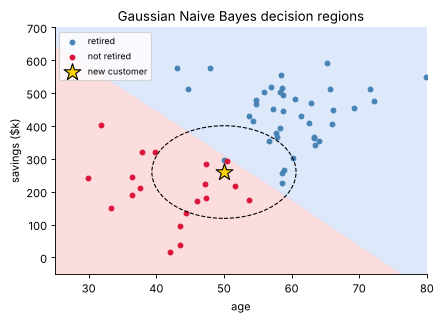

GaussianNB P(retired | X) = 0.19


In [10]:
from sklearn.naive_bayes import GaussianNB

X_pts = np.vstack([blue, red]); y_pts = np.r_[np.ones(40), np.zeros(20)]
gnb = GaussianNB().fit(X_pts, y_pts)
xx, yy = np.meshgrid(np.linspace(25, 80, 200), np.linspace(-50, 700, 200))
zz = gnb.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 4))
ax.contourf(xx, yy, zz, levels=[0, 0.5, 1], colors=["#fbd5d5", "#d5e3fb"], alpha=0.8)
ax.scatter(*blue.T, color="steelblue", s=18, label="retired")
ax.scatter(*red.T, color="crimson", s=18, label="not retired")
ax.add_patch(plt.matplotlib.patches.Ellipse(X_new, 2 * radius * sd[0], 2 * radius * sd[1],
                                            fill=False, ls="--", color="black"))
ax.scatter(*X_new, marker="*", s=250, color="gold", edgecolor="black", zorder=5, label="new customer")
ax.set_xlabel("age"); ax.set_ylabel("savings ($k)"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Gaussian Naive Bayes decision regions"); plt.show()
print("GaussianNB P(retired | X) =", gnb.predict_proba([X_new])[0, 1].round(2))

Blue has the larger prior (twice as many retired customers), but `X` sits among the red points, and the likelihood
outweighs the prior: `X` is classified as not ready to retire. The Gaussian version in scikit-learn, which models each
feature with a bell curve per class instead of counting neighbours, agrees.

The "naive" part is an assumption: features are treated as independent within each class, so the likelihood of `X` is
just the product of the likelihoods of its individual features. That's rarely true (age and savings are clearly
related), but the ranking of classes usually survives, and the assumption is what makes the model so fast. With
thousands of word features it's the only reason the model is tractable at all.

scikit-learn has three common variants:

| Variant | Feature type | Typical use |
|---|---|---|
| `GaussianNB` | Continuous, roughly normal | Measurements like age, savings |
| `MultinomialNB` | Counts | Word counts in documents |
| `BernoulliNB` | Binary present/absent | Whether a word appears |

<a id="cleaning-text-punctuation-and-stop-words"></a>

### Cleaning Text: Punctuation and Stop Words

Before counting words, strip what carries no signal:

- **Punctuation**: `string.punctuation` lists the ASCII punctuation characters.
- **Stop words**: very common words such as "the", "is", "and" that appear in every document. scikit-learn ships a list
  of 318 English stop words; NLTK's `stopwords.words("english")` is a popular alternative (it needs a one-off
  `nltk.download("stopwords")`).

In [11]:
import string
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def clean_text(message):
    """Lowercase, remove punctuation and stop words, return a list of tokens."""
    no_punct = "".join(ch for ch in message.lower() if ch not in string.punctuation)
    return [w for w in no_punct.split() if w not in ENGLISH_STOP_WORDS and w.isprintable()]

sample = "Hello Mr. Future, I am so happy to be learning AI now!!"
print(string.punctuation)
print(clean_text(sample))

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~
['hello', 'mr', 'future', 'happy', 'learning', 'ai']


<a id="bag-of-words-countvectorizer-and-tf-idf"></a>

### Bag of Words: CountVectorizer and TF-IDF

A **bag of words** represents each document as a vector of word counts over a fixed vocabulary. Order is thrown away;
only which words occur, and how often, survives. `CountVectorizer` learns the vocabulary in `fit` and produces a sparse
matrix (mostly zeros) in `transform`.

```mermaid
flowchart LR
    A["Raw text"] --> B["Clean:<br/>lowercase, punctuation,<br/>stop words"]
    B --> C["Tokens"]
    C --> D["CountVectorizer:<br/>vocabulary + counts"]
    D --> E["Sparse matrix<br/>documents × words"]
    E --> F["MultinomialNB"]
```

**TF-IDF** (term frequency × inverse document frequency) re-weights the counts: words frequent in one document but
rare across the collection get boosted, words that appear everywhere get damped.

**Watch out:** `vectorizer.get_feature_names()` was removed in scikit-learn 1.2. Use `get_feature_names_out()`.

In [12]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

docs = ["This is the first document.", "This document is the second document.",
        "And this is the third one.", "Is this the first document?"]
cv = CountVectorizer()
counts = cv.fit_transform(docs)
print(pd.DataFrame(counts.toarray(), columns=cv.get_feature_names_out()).to_string())

tfidf = TfidfVectorizer().fit(docs)
print("\nTF-IDF weights, document 2:")
print(pd.Series(tfidf.transform(docs[1:2]).toarray()[0], tfidf.get_feature_names_out()).round(2)
      .loc[lambda s: s > 0].to_string())

   and  document  first  is  one  second  the  third  this
0    0         1      1   1    0       0    1      0     1
1    0         2      0   1    0       1    1      0     1
2    1         0      0   1    1       0    1      1     1
3    0         1      1   1    0       0    1      0     1

TF-IDF weights, document 2:
document    0.69
is          0.28
second      0.54
the         0.28
this        0.28


In document 2, "second" (unique to it) gets the highest TF-IDF weight and "document" (twice, but common) comes next,
while "is", "the" and "this" (in every document) are pushed down.

<a id="10-project-filtering-spam-e-mails"></a>

## 10. Project: Filtering Spam E-mails

A spam filter reads an e-mail and decides whether it's spam (1) or legitimate "ham" (0). The dataset has 5,728 e-mails
with their subject lines and bodies.

<a id="exploring-the-e-mails"></a>

### Exploring the E-mails

Every e-mail starts with its subject line. A quick check for duplicates, the class balance, and lengths.

In [13]:
spam_df = pd.read_csv(DATA / "emails.csv")
print(spam_df.shape, "| duplicates:", spam_df.duplicated().sum())
spam_df = spam_df.drop_duplicates().reset_index(drop=True)
spam_df["length"] = spam_df["text"].str.len()

print(spam_df["spam"].value_counts(normalize=True).rename({0: "ham", 1: "spam"}).round(3).to_string())
print(spam_df.groupby("spam")["length"].describe()[["mean", "50%", "max"]].round(0).to_string())
print("\n", spam_df.loc[spam_df["spam"] == 1, "text"].iloc[0][:160], "...")

(5728, 2) | duplicates: 33
spam
ham     0.76
spam    0.24
        mean     50%      max
spam                         
0     1634.0  1122.0  43952.0
1     1317.0   694.0  28432.0

 Subject: naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isove ...


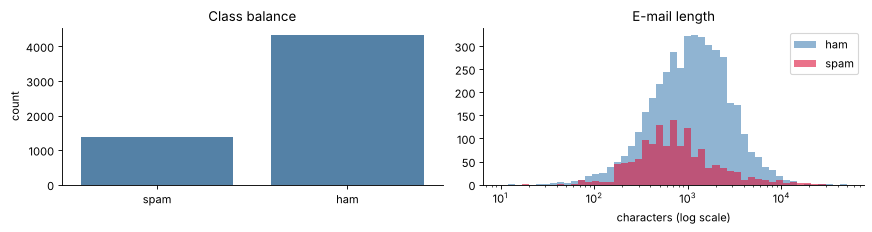

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3))
sns.countplot(x=spam_df["spam"].map({0: "ham", 1: "spam"}), ax=ax1, color="steelblue"); ax1.set_xlabel("")
ax1.set_title("Class balance")
bins = np.logspace(1, 4.7, 50)
for label, name, color in ((0, "ham", "steelblue"), (1, "spam", "crimson")):
    ax2.hist(spam_df.loc[spam_df["spam"] == label, "length"], bins=bins, alpha=0.6, label=name, color=color)
ax2.set_xscale("log"); ax2.set_xlabel("characters (log scale)"); ax2.set_title("E-mail length"); ax2.legend()
plt.tight_layout(); plt.show()

About a quarter of the e-mails are spam, and the two length distributions overlap heavily, so length alone won't
separate them. The words will.

<a id="a-pipeline-that-cant-leak"></a>

### A Pipeline That Can't Leak

The vectorizer learns a vocabulary, so it's a fitted step just like an imputer or scaler, and the
[pipeline rule from section 7](#pipelines-preprocessing-and-model-as-one-object) applies: fitting it on all e-mails
before splitting lets words that appear only in test e-mails into the training features.

**Watch out:** a common version of this project fits `CountVectorizer` on the whole dataset and even trains the first
model on all of it before splitting. Put the vectorizer and the model in one `Pipeline` and split the raw text first;
then `fit` touches only training data.

`stratify=y` keeps the spam proportion identical in both splits.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    spam_df["text"], spam_df["spam"], test_size=0.2, stratify=spam_df["spam"], random_state=42)

spam_model = make_pipeline(CountVectorizer(analyzer=clean_text), MultinomialNB())
spam_model.fit(X_train, y_train)
vocab = spam_model.named_steps["countvectorizer"].get_feature_names_out()
print(f"vocabulary: {len(vocab):,} words | sample: {list(vocab[5000:5006])}")

y_pred = spam_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=3))

vocabulary: 33,451 words | sample: ['atlantic', 'atlanticasp', 'atlas', 'atleast', 'atlons', 'atm']
              precision    recall  f1-score   support

         ham      0.998     0.993     0.995       865
        spam      0.978     0.993     0.986       274

    accuracy                          0.993      1139
   macro avg      0.988     0.993     0.990      1139
weighted avg      0.993     0.993     0.993      1139



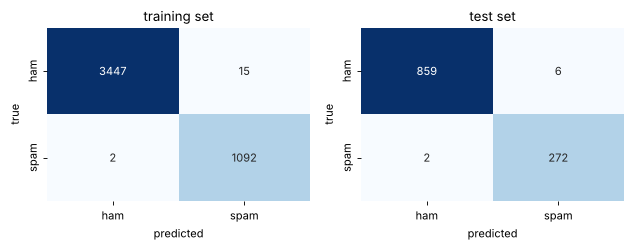

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, (X_, y_, name) in zip(axes, [(X_train, y_train, "training"), (X_test, y_test, "test")]):
    sns.heatmap(confusion_matrix(y_, spam_model.predict(X_)), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"], ax=ax)
    ax.set_title(f"{name} set"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

In spam terms ([precision and recall are defined in section 7](#classification-metrics-precision-recall-and-f1)),
a false positive sends a real e-mail to the junk folder and a false negative lets spam through. For a spam filter,
precision on spam usually matters more: users forgive a stray spam in the inbox more readily than a lost
invoice.

<a id="what-the-model-learned"></a>

### What the Model Learned

Multinomial Naive Bayes stores, for each class, the (smoothed) log probability of every word. The words with the
largest difference between the spam and ham log probabilities are the model's strongest evidence.

In [17]:
nb = spam_model.named_steps["multinomialnb"]
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
order = np.argsort(log_ratio)
print("most spammy:", ", ".join(vocab[order[-12:]][::-1]))
print("most hammy: ", ", ".join(vocab[order[:12]]))

most spammy: viagra, projecthoneypot, stationery, squirrelmail, sex, paypal, oem, andmanyother, oniine, dose, mailwisconsin, qmail
most hammy:  enron, ect, kaminski, vince, crenshaw, 713, stinson, ees, kevin, gibner, hou, shirley


The ham side is full of names and words from one company's internal e-mail (this dataset comes from Enron's
mailboxes), which is a reminder that a filter learns the mailbox it was trained on. It would need retraining for a
different user.

<a id="trying-tf-idf-and-scoring-new-e-mails"></a>

### Trying TF-IDF and Scoring New E-mails

Does re-weighting the counts with TF-IDF help? And because the vectorizer lives inside the pipeline, new e-mails go in as plain strings.

In [18]:
from sklearn.feature_extraction.text import TfidfTransformer

spam_tfidf = make_pipeline(CountVectorizer(analyzer=clean_text), TfidfTransformer(), MultinomialNB())
spam_tfidf.fit(X_train, y_train)
from sklearn.metrics import f1_score
for name, mdl in (("counts", spam_model), ("TF-IDF", spam_tfidf)):
    print(f"{name:7} macro F1 {f1_score(y_test, mdl.predict(X_test), average='macro'):.3f}")

new_mail = ["Free money!!! Claim your prize now, limited offer",
            "Hi Kim, please let me know if you need any further information. Thanks",
            "Hello, I am Ryan, I would like to book a hotel in Bali by January 24th"]
print(spam_model.predict(new_mail), spam_model.predict_proba(new_mail)[:, 1].round(3))

counts  macro F1 0.990
TF-IDF  macro F1 0.833
[1 0 0] [1. 0. 0.]


TF-IDF doesn't automatically help Multinomial Naive Bayes: the model was designed for raw counts, and TF-IDF can shrink
the very words that mark spam. Always measure instead of assuming. Because the whole pipeline is one object, scoring
new e-mails takes raw strings directly.

**Cheatsheet: text classification with scikit-learn**

| Step | Code |
|---|---|
| Custom cleaning | `CountVectorizer(analyzer=clean_text)` (function returns a token list) |
| Built-in cleaning | `CountVectorizer(lowercase=True, stop_words="english")` |
| No leakage | `make_pipeline(CountVectorizer(...), MultinomialNB())` fitted on training text only |
| Vocabulary | `vectorizer.get_feature_names_out()` |
| TF-IDF | `TfidfVectorizer()` or `TfidfTransformer()` after counts |
| Per-class metrics | `classification_report(y_test, y_pred)` |
| Top words | `nb.feature_log_prob_[1] - nb.feature_log_prob_[0]` |

#### Exercise 5

Estimate the spam filter's performance more robustly with 5-fold stratified cross-validation on the training set.
Report the mean and standard deviation of the F1 score for the spam class.

#### Solution 5

*Try it yourself before running this cell.*

In [19]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

scores = cross_val_score(make_pipeline(CountVectorizer(analyzer=clean_text), MultinomialNB()),
                         X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="f1")
print(f"F1 (spam): {scores.mean():.3f} ± {scores.std():.3f}")

F1 (spam): 0.980 ± 0.005


<a id="11-project-classifying-yelp-reviews"></a>

## 11. Project: Classifying Yelp Reviews

Yelp publishes crowd-sourced reviews of businesses, each with a 1–5 star rating. Other users can vote a review "cool",
"useful" or "funny"; those votes rate the review, not the business. The question: can we tell a 1-star review from a
5-star one from its text alone?

<a id="exploring-stars-and-review-length"></a>

### Exploring Stars and Review Length

Ten thousand reviews, each with its star rating, the votes from other users, and the text.

In [20]:
yelp_df = pd.read_csv(DATA / "yelp.csv")
yelp_df["length"] = yelp_df["text"].str.len()
print(yelp_df.shape)
print(yelp_df[["stars", "cool", "useful", "funny", "length"]].describe().loc[["mean", "50%", "max"]].round(1).to_string())
print("\nshortest review:", repr(yelp_df.loc[yelp_df["length"].idxmin(), "text"]))

(10000, 11)
      stars  cool  useful  funny  length
mean    3.8   0.9     1.4    0.7   710.7
50%     4.0   0.0     1.0    0.0   541.5
max     5.0  77.0    76.0   57.0  4997.0

shortest review: 'X'


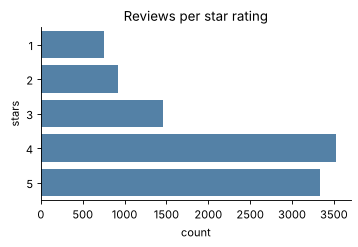

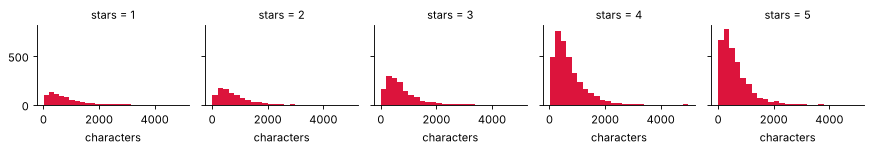

In [21]:
fig, ax = plt.subplots(figsize=(5, 2.8))
sns.countplot(y=yelp_df["stars"], ax=ax, color="steelblue"); ax.set_title("Reviews per star rating"); plt.show()

g = sns.FacetGrid(yelp_df, col="stars", col_wrap=5, height=2, aspect=1.1)
g.map(plt.hist, "length", bins=25, color="crimson"); g.set_axis_labels("characters", "")
plt.show()

Most reviews are positive: 4 and 5 stars make up two-thirds of the data. Length distributions look similar across
ratings, with a long tail of essays in every class.

<a id="1-star-vs-5-stars"></a>

### 1 Star vs. 5 Stars

Keeping only the extremes gives a clean binary problem, and an imbalanced one: about 18% of the remaining reviews are
1-star. Watch the minority class.

In [22]:
yelp_1_5 = yelp_df[yelp_df["stars"].isin([1, 5])].reset_index(drop=True)
print(yelp_1_5["stars"].value_counts(normalize=True).round(3).to_string())

X_train, X_test, y_train, y_test = train_test_split(
    yelp_1_5["text"], yelp_1_5["stars"], test_size=0.2, stratify=yelp_1_5["stars"], random_state=42)
yelp_model = make_pipeline(CountVectorizer(analyzer=clean_text), MultinomialNB()).fit(X_train, y_train)
print(classification_report(y_test, yelp_model.predict(X_test), digits=3))

stars
5    0.817
1    0.183


              precision    recall  f1-score   support

           1      0.907     0.647     0.755       150
           5      0.925     0.985     0.954       668

    accuracy                          0.923       818
   macro avg      0.916     0.816     0.855       818
weighted avg      0.922     0.923     0.918       818



The headline accuracy is 92%, but look at the 1-star row: only 65% of the 1-star reviews are caught, against 98% of
the 5-star ones. With
five times more positive reviews, the prior pulls borderline cases towards 5 stars. If the business goal is to catch
unhappy customers, that's the number to improve.

<a id="handling-the-imbalance"></a>

### Handling the Imbalance

Two simple options:

- **ComplementNB** estimates each class's word statistics from all the *other* classes, which is more stable when one
  class is small. It's often better than MultinomialNB on imbalanced text.
- **Equal priors**: tell Multinomial NB not to use the class frequencies (`fit_prior=False`), so neither class gets a
  head start.

Balanced accuracy (the mean of per-class recall) is a fairer single number than accuracy here.

In [23]:
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import balanced_accuracy_score, recall_score

candidates = {
    "MultinomialNB": MultinomialNB(),
    "MultinomialNB, equal priors": MultinomialNB(fit_prior=False),
    "ComplementNB": ComplementNB(),
}
for name, clf in candidates.items():
    p = make_pipeline(CountVectorizer(analyzer=clean_text), clf).fit(X_train, y_train).predict(X_test)
    print(f"{name:29} balanced acc {balanced_accuracy_score(y_test, p):.3f} | "
          f"1-star recall {recall_score(y_test, p, pos_label=1):.3f}")

MultinomialNB                 balanced acc 0.816 | 1-star recall 0.647


MultinomialNB, equal priors   balanced acc 0.851 | 1-star recall 0.727


ComplementNB                  balanced acc 0.851 | 1-star recall 0.727


Both changes lift 1-star recall from 0.65 to 0.73 at a small cost in 5-star recall. With exactly two classes they give
the same predictions, because ComplementNB's main effect in the binary case is to remove the prior's head start. With
three or more imbalanced classes they differ, and ComplementNB is usually the better default.

In [24]:
reviews = ["amazing food! highly recommended", "terrible food, made me sick",
           "the service was slow but the pasta was worth the wait"]
print(dict(zip(reviews, yelp_model.predict(reviews))))

{'amazing food! highly recommended': np.int64(5), 'terrible food, made me sick': np.int64(1), 'the service was slow but the pasta was worth the wait': np.int64(5)}


#### Exercise 6

Use all five star ratings: label 1–2 stars as `negative`, 3 as `neutral` and 4–5 as `positive`. Train a
`CountVectorizer(analyzer=clean_text)` + `ComplementNB` pipeline and print the classification report. Which class is
hardest?

#### Solution 6

*Try it yourself before running this cell.*

In [25]:
sentiment = pd.cut(yelp_df["stars"], bins=[0, 2, 3, 5], labels=["negative", "neutral", "positive"])
Xa, Xb, ya, yb = train_test_split(yelp_df["text"], sentiment, test_size=0.2, stratify=sentiment, random_state=0)
three = make_pipeline(CountVectorizer(analyzer=clean_text), ComplementNB()).fit(Xa, ya)
print(classification_report(yb, three.predict(Xb), digits=3))
# Neutral is hardest: 3-star reviews mix praise and complaints, so their words overlap both other classes.

              precision    recall  f1-score   support

    negative      0.647     0.645     0.646       335
     neutral      0.264     0.048     0.081       292
    positive      0.810     0.952     0.875      1373

    accuracy                          0.768      2000
   macro avg      0.574     0.548     0.534      2000
weighted avg      0.703     0.768     0.721      2000



<a id="12-project-a-movie-recommender-from-ratings"></a>

## 12. Project: A Movie Recommender from Ratings

Recommender systems suggest movies, products or songs a user is likely to rate highly, based on past behaviour: "people
who liked this also liked…". We'll build one from the MovieLens 100k dataset, 100,000 ratings (1–5 stars) from 943 users
on 1,682 movies. This copy also contains a sample user `0` with three ratings, which is why the counts below say 944.

<a id="collaborative-filtering-user-based-and-item-based"></a>

### Collaborative Filtering: User-Based and Item-Based

**Collaborative filtering** uses only the ratings matrix, with no knowledge of genres or actors. There are two flavours:

- **User-based**: find users whose past ratings resemble yours, and recommend what they liked that you haven't seen.
- **Item-based**: find movies whose rating patterns resemble the ones you liked. Two movies are similar if the same
  people tend to rate them the same way.

```mermaid
flowchart LR
    subgraph U["User-based"]
        direction TB
        u1["You liked A, B"] --> u2["Similar users<br/>also liked A, B"]
        u2 --> u3["They liked C<br/>→ recommend C"]
    end
    subgraph I["Item-based"]
        direction TB
        i1["You liked A"] --> i2["Movies whose ratings<br/>correlate with A's"]
        i2 --> i3["Recommend the<br/>most correlated"]
    end
```

Item-based filtering is the more common choice in practice: there are far fewer items than users, item similarities
change slowly, and they can be precomputed. That's what we build here, using the **Pearson correlation** between two
movies' rating columns as the similarity.

<a id="loading-and-exploring-ratings"></a>

### Loading and Exploring Ratings

Ratings come as `user_id, item_id, rating, timestamp` rows; a second file maps item ids to titles.

In [26]:
titles = pd.read_csv(DATA / "movielens" / "movie-titles.csv")
ratings = pd.read_csv(DATA / "movielens" / "u.data", sep="\t",
                      names=["user_id", "item_id", "rating", "timestamp"]).drop(columns="timestamp")
ratings = ratings.merge(titles, on="item_id")
print(ratings.shape, "| users", ratings["user_id"].nunique(), "| movies", ratings["title"].nunique())
print(ratings.head(3).to_string(index=False))

stats = ratings.groupby("title")["rating"].agg(["count", "mean"])
print("\nperfect 5.0 average:", (stats["mean"] == 5).sum(), "movies, with at most",
      stats.loc[stats["mean"] == 5, "count"].max(), "ratings each")
print(stats.sort_values("count", ascending=False).head(5).round(2).to_string())

(100003, 4) | users 944 | movies 1664
 user_id  item_id  rating                           title
       0       50       5                Star Wars (1977)
       0      172       5 Empire Strikes Back, The (1980)
       0      133       1       Gone with the Wind (1939)

perfect 5.0 average: 10 movies, with at most 3 ratings each
                           count  mean
title                                 
Star Wars (1977)             584  4.36
Contact (1997)               509  3.80
Fargo (1996)                 508  4.16
Return of the Jedi (1983)    507  4.01
Liar Liar (1997)             485  3.16


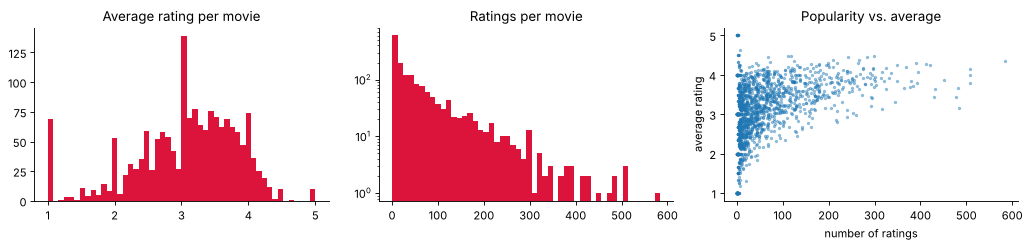

In [27]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.2))
ax1.hist(stats["mean"], bins=50, color="crimson"); ax1.set_title("Average rating per movie")
ax2.hist(stats["count"], bins=50, color="crimson"); ax2.set_title("Ratings per movie"); ax2.set_yscale("log")
ax3.scatter(stats["count"], stats["mean"], s=4, alpha=0.4); ax3.set_xlabel("number of ratings")
ax3.set_ylabel("average rating"); ax3.set_title("Popularity vs. average")
plt.tight_layout(); plt.show()

The ten movies with a perfect 5.0 average were rated by three people or fewer, while the most-rated films sit around 3.5
to 4.5. Averages from tiny samples are noise. The scatter plot makes the point: the extremes (1.0 and 5.0) only occur
at the far left. Any similarity we compute needs a **minimum number of overlapping ratings** to be trustworthy.

<a id="movies-similar-to-one-movie"></a>

### Movies Similar to One Movie

Pivot the ratings into a user × movie matrix (mostly empty: each user rated about 6% of the movies). Each column is
one movie's ratings across users. `corrwith` correlates every column with one chosen movie, using only users who rated
both.

In [28]:
matrix = ratings.pivot_table(index="user_id", columns="title", values="rating")
print(matrix.shape, f"| filled: {matrix.notna().mean().mean():.1%}")

def similar_to(title, min_count=80, n=6):
    corr = matrix.corrwith(matrix[title]).rename("correlation").to_frame().join(stats["count"]).dropna()
    return corr[corr["count"] >= min_count].sort_values("correlation", ascending=False).head(n)

print(similar_to("Titanic (1997)").round(3).to_string())

(944, 1664) | filled: 6.3%


                                               correlation  count
title                                                            
Titanic (1997)                                       1.000    350
River Wild, The (1994)                               0.498    146
Abyss, The (1989)                                    0.472    151
Bram Stoker's Dracula (1992)                         0.444    120
True Lies (1994)                                     0.435    208
William Shakespeare's Romeo and Juliet (1996)        0.430    106


The movie itself always comes first with a correlation of 1. Without `min_count`, the top of the list fills with
obscure films that happen to correlate perfectly with Titanic through two or three shared viewers. Requiring at least 80
ratings filters those out; the price is that niche movies can never be recommended. That's the classic **popularity
bias** of correlation-based recommenders.

In [29]:
print(similar_to("Star Wars (1977)").round(3).to_string())

                                                    correlation  count
title                                                                 
Star Wars (1977)                                          1.000    584
Empire Strikes Back, The (1980)                           0.748    368
Return of the Jedi (1983)                                 0.673    507
Raiders of the Lost Ark (1981)                            0.536    420
Austin Powers: International Man of Mystery (1997)        0.377    130
Sting, The (1973)                                         0.368    241


<a id="recommendations-from-your-own-ratings"></a>

### Recommendations from Your Own Ratings

For a full recommender, precompute the movie × movie correlation matrix once, with `min_periods=80` so pairs with too
few common raters come out as `NaN`. Then for each movie you rated, take its similarity column, weight it by how much you
liked that movie, and add everything up.

**Watch out:** two problems in the usual version of this step:

1. `pd.Series().append()` was removed in pandas 2.0. Collect the pieces in a list and `pd.concat` them.
2. Weighting similarities by the raw rating treats a 1-star rating as a weak *positive* vote, so movies similar to
   something you hated still climb the list. Centre the rating first (`rating - 3`), so dislikes subtract.

In [30]:
movie_corr = matrix.corr(method="pearson", min_periods=80)
my_ratings = pd.read_csv(DATA / "movielens" / "my-ratings.csv")
print(my_ratings.to_string(index=False))

def recommend(my_ratings, center=None, n=8):
    pieces = []
    for title, rating in zip(my_ratings["Movie Name"], my_ratings["Ratings"]):
        weight = rating if center is None else rating - center
        pieces.append(movie_corr[title].dropna() * weight)
    scores = pd.concat(pieces).groupby(level=0).sum()
    return scores.drop(my_ratings["Movie Name"], errors="ignore").sort_values(ascending=False).head(n)

raw, centred = recommend(my_ratings), recommend(my_ratings, center=3)
print(pd.DataFrame({"raw ratings as weights": raw.index, "centred ratings": centred.index}).to_string(index=False))

      Movie Name  Ratings
Liar Liar (1997)        5
Star Wars (1977)        1
                   raw ratings as weights                    centred ratings
                           Con Air (1997)                   G.I. Jane (1997)
                      Pretty Woman (1990)                Multiplicity (1996)
Indiana Jones and the Last Crusade (1989)               Jungle2Jungle (1997)
                           Michael (1996)       First Wives Club, The (1996)
                           Top Gun (1986) Father of the Bride Part II (1995)
                Back to the Future (1985)        George of the Jungle (1997)
       Ghost and the Darkness, The (1996)                      Ransom (1996)
                   Field of Dreams (1989)            Grumpier Old Men (1995)


With raw weights, the 1-star rating of Star Wars still adds `+1 × similarity`, so the adventure films Star Wars fans
love (Indiana Jones, Back to the Future, Top Gun) land in the list of someone who disliked it. Centred weights make the
dislike count against them, and the list becomes mostly broad comedies close to Liar Liar. Removing the
movies you've already rated (`drop`) is the other fix most toy recommenders forget.

**Cheatsheet: item-based collaborative filtering**

| Step | Code |
|---|---|
| Ratings matrix | `ratings.pivot_table(index="user_id", columns="title", values="rating")` |
| Popularity stats | `ratings.groupby("title")["rating"].agg(["count", "mean"])` |
| Similar to one item | `matrix.corrwith(matrix[title])`, then filter on `count` |
| All item pairs | `matrix.corr(min_periods=80)` |
| Score a user | `sum((rating - 3) * movie_corr[rated_title])` over rated titles |
| Clean the list | drop already-rated titles, sort descending |

#### Exercise 7

Build a **user-based** recommendation for user 1. Find the 20 users whose ratings correlate most with user 1's
(at least 15 movies in common), average their ratings for movies user 1 hasn't seen, keep
movies rated by at least 5 of those neighbours, and print the top 8.

#### Solution 7

*Try it yourself before running this cell.*

In [31]:
by_user = matrix.T                                       # movies x users
me = by_user[1]
overlap = by_user.notna().astype(int).T @ me.notna().astype(int)
sims = by_user.corrwith(me)[overlap >= 15].drop(1).nlargest(20)
neighbours = matrix.loc[sims.index]
unseen = neighbours.loc[:, me.isna()]
recs = unseen.mean()[unseen.notna().sum() >= 5].sort_values(ascending=False).head(8)
print(recs.round(2).to_string())

title
Boot, Das (1981)            4.80
Schindler's List (1993)     4.80
Trainspotting (1996)        4.43
L.A. Confidential (1997)    4.33
Face/Off (1997)             4.20
Leaving Las Vegas (1995)    4.00
Titanic (1997)              4.00
Sleepers (1996)             4.00
